# Part B (Mohamad): model comparison, one-time test, split sensitivity
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | What happens | Course |
|---|---|---|
| 0 | Load every model's validation and test probabilities | |
| 1 | Choose each model's decision threshold on the **validation** set | R3.2: the threshold is a choice |
| 2 | Development comparison and the selection rule (written **before** testing) → final model | R6 §11 |
| 3 | Evaluate every frozen model **once** on the test set | R4: test once |
| 4 | Level 2 vs Level 1: what does the neural network improve? | Project brief |
| 5 | Threshold table for the final model | R3.2 |
| 6 | Split sensitivity: star vs random folds, and 3 new train/val/test splits | R4 §4 |

## Step 0: load the predictions

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold, KFold, GroupShuffleSplit, cross_val_score
warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from features import get_X, make_scaled_pipeline, RANDOM_STATE

RES, FIG, MODELS = ROOT / "results", ROOT / "results" / "figures", ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)

NAMES = ["Baseline", "LogReg", "DecisionTree", "RandomForest", "AdaBoost", "NeuralNet"]
LEVEL = {"Baseline": "baseline", "NeuralNet": "Level 2"}
COLORS = {"Baseline": "#9c9a92", "LogReg": "#2a78d6", "DecisionTree": "#eda100", "RandomForest": "#eb6834",
          "AdaBoost": "#1baf7a", "NeuralNet": "#6250d6"}

preds = None
for name in NAMES:
    p = pd.read_csv(RES / f"preds_{name}.csv")[["kepoi_name", "split", "label", "p"]].rename(columns={"p": name})
    preds = p if preds is None else preds.merge(p.drop(columns="label"), on=["kepoi_name", "split"], how="inner")
val, test = preds[preds.split == "val"].reset_index(drop=True), preds[preds.split == "test"].reset_index(drop=True)
print(f"validation KOIs: {len(val)} | test KOIs: {len(test)} | models: {NAMES}")

validation KOIs: 1522 | test KOIs: 1546 | models: ['Baseline', 'LogReg', 'DecisionTree', 'RandomForest', 'AdaBoost', 'NeuralNet']


In [2]:
def scores(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"F1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "accuracy": accuracy_score(y, pred),
            "FPR": fp / (fp + tn), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

## Step 1: decision thresholds, chosen on the validation set
The default threshold 0.5 is not always best (Recitation 3.2). For each model we try thresholds 0.05 to 0.95 on
the **validation** set and keep the one with the highest F1. The same rule is applied to every model, and the test
set is not used.

In [3]:
GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
THR = {}
for name in NAMES:
    if name == "Baseline":
        THR[name] = 0.5           # the baseline always predicts "false positive": no threshold to tune
        continue
    f1s = [f1_score(val.label, val[name] >= t, zero_division=0) for t in GRID]
    THR[name] = float(GRID[int(np.argmax(f1s))])

dev = pd.DataFrame({name: {"level": LEVEL.get(name, "Level 1"), "threshold": THR[name],
                           "val F1 @0.5": scores(val.label, val[name], 0.5)["F1"],
                           **{f"val {k}": v for k, v in scores(val.label, val[name], THR[name]).items()
                              if k in ("F1", "precision", "recall", "accuracy")}}
                    for name in NAMES}).T
dev

,level,threshold,val F1 @0.5,val F1,val precision,val recall,val accuracy
Baseline,baseline,0.5,0.0,0.0,0.0,0.0,0.624179
LogReg,Level 1,0.58,0.93172,0.933566,0.933566,0.933566,0.950066
DecisionTree,Level 1,0.9,0.913118,0.915725,0.91019,0.921329,0.936268
RandomForest,Level 1,0.39,0.951198,0.953043,0.948097,0.958042,0.96452
AdaBoost,Level 1,0.5,0.949565,0.949565,0.944637,0.954545,0.961892
NeuralNet,Level 2,0.68,0.950478,0.953139,0.964222,0.942308,0.965177


## Step 2: development comparison and the selection rule
Recitation 6: *the highest validation score is not automatically the best practical choice*, so we also weigh
simplicity and interpretability. **Rule, written before looking at the test set:** take the model with the highest
validation F1; if a **simpler** model is within **0.01** of it, take the simpler one (the difference is within the
noise; Hend's seed check shows the network alone varies by about ±0.003).

Simplicity order: logistic regression < decision tree < Random Forest = AdaBoost < neural network.

In [4]:
SIMPLICITY = {"LogReg": 0, "DecisionTree": 1, "RandomForest": 2, "AdaBoost": 2, "NeuralNet": 3}
INTERPRETABILITY = {"Baseline": "-", "LogReg": "high (weights)", "DecisionTree": "high (if shallow)",
                    "RandomForest": "medium-low", "AdaBoost": "medium-low", "NeuralNet": "low"}
dev["interpretability"] = pd.Series(INTERPRETABILITY)

candidates = [n for n in NAMES if n != "Baseline"]
best = max(candidates, key=lambda n: dev.loc[n, "val F1"])
close = [n for n in candidates if dev.loc[best, "val F1"] - dev.loc[n, "val F1"] <= 0.01]
FINAL = min(close, key=lambda n: (SIMPLICITY[n], -dev.loc[n, "val F1"]))
best_l1 = max([n for n in candidates if n != "NeuralNet"], key=lambda n: dev.loc[n, "val F1"])

print(f"highest validation F1: {best} ({dev.loc[best, 'val F1']:.4f})")
print(f"within 0.01 of it:    {close}")
print(f"==> FINAL MODEL: {FINAL} (threshold {THR[FINAL]:.2f})  |  best Level-1 model: {best_l1}")
json.dump({"final_model": FINAL, "threshold": THR[FINAL], "thresholds": THR, "best_level1": best_l1,
           "rule": "highest validation F1; a simpler model within 0.01 is preferred"},
          open(RES / "final_choice.json", "w"), indent=2)
dev.to_csv(RES / "B7_development_comparison.csv")
dev[["level", "threshold", "val F1", "val precision", "val recall", "interpretability"]].round(4)

highest validation F1: NeuralNet (0.9531)
within 0.01 of it:    ['RandomForest', 'AdaBoost', 'NeuralNet']
==> FINAL MODEL: RandomForest (threshold 0.39)  |  best Level-1 model: RandomForest


,level,threshold,val F1,val precision,val recall,interpretability
Baseline,baseline,0.5,0.0,0.0,0.0,-
LogReg,Level 1,0.58,0.933566,0.933566,0.933566,high (weights)
DecisionTree,Level 1,0.9,0.915725,0.91019,0.921329,high (if shallow)
RandomForest,Level 1,0.39,0.953043,0.948097,0.958042,medium-low
AdaBoost,Level 1,0.5,0.949565,0.944637,0.954545,medium-low
NeuralNet,Level 2,0.68,0.953139,0.964222,0.942308,low


## Step 3: the one-time test
Everything is now frozen: features, hyper-parameters, thresholds and the final model (saved in
`results/final_choice.json`). Every model is evaluated **once** on the test set (20 % of the stars, never used
before). Nothing is changed after this cell.

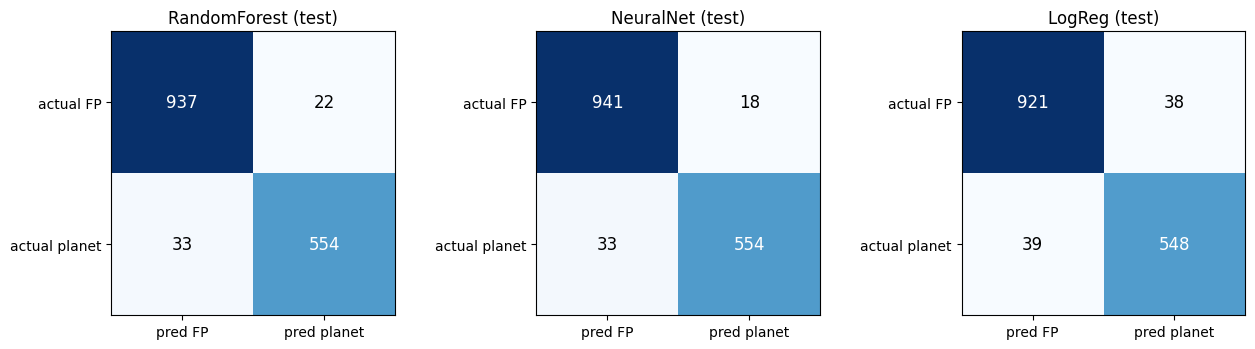

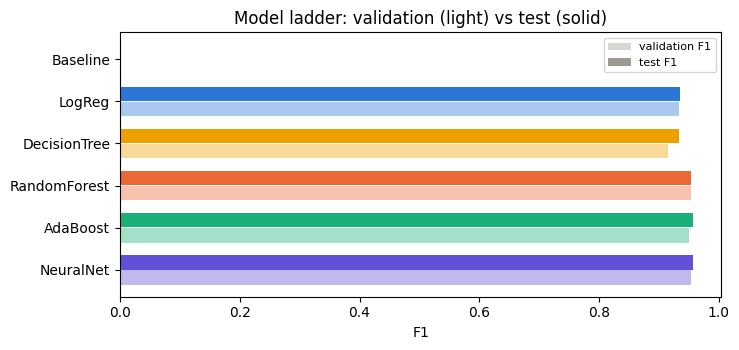

,level,threshold,F1,precision,recall,accuracy,FPR,val F1
Baseline,baseline,0.50,0.0000,0.0000,0.0000,0.6203,0.0000,0.0000
LogReg,Level 1,0.58,0.9344,0.9352,0.9336,0.9502,0.0396,0.9336
DecisionTree,Level 1,0.90,0.9330,0.9291,0.9370,0.9489,0.0438,0.9157
RandomForest,Level 1,0.39,0.9527,0.9618,0.9438,0.9644,0.0229,0.9530
AdaBoost,Level 1,0.50,0.9564,0.9605,0.9523,0.9670,0.0240,0.9496
NeuralNet,Level 2,0.68,0.9560,0.9685,0.9438,0.9670,0.0188,0.9531


In [5]:
test_table = pd.DataFrame({n: {"level": LEVEL.get(n, "Level 1"), "threshold": THR[n], **scores(test.label, test[n], THR[n])}
                           for n in NAMES}).T
test_table["val F1"] = dev["val F1"]
test_table.to_csv(RES / "B7_test_results.csv")
test[["kepoi_name", "label"] + NAMES].rename(columns={n: f"p_{n}" for n in NAMES}).to_csv(RES / "test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, n in zip(axes, dict.fromkeys([FINAL, best_l1, "NeuralNet", "LogReg"]).__iter__()):
    cm = confusion_matrix(test.label, test[n] >= THR[n], labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=12, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred FP", "pred planet"]); ax.set_yticks([0, 1], ["actual FP", "actual planet"])
    ax.set_title(f"{n} (test)")
plt.tight_layout(); plt.savefig(FIG / "B7_confusion_matrices.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(NAMES))
ax.barh(yy + 0.18, test_table["val F1"].astype(float), height=0.34, color=[COLORS[n] for n in NAMES], alpha=0.4, label="validation F1")
ax.barh(yy - 0.18, test_table["F1"].astype(float), height=0.34, color=[COLORS[n] for n in NAMES], label="test F1")
ax.set_yticks(yy, NAMES); ax.invert_yaxis(); ax.set_xlabel("F1"); ax.legend(fontsize=8)
ax.set_title("Model ladder: validation (light) vs test (solid)")
plt.tight_layout(); plt.savefig(FIG / "B7_model_ladder.png", dpi=200); plt.show()
test_table[["level", "threshold", "F1", "precision", "recall", "accuracy", "FPR", "val F1"]].astype(
    {c: float for c in ["threshold", "F1", "precision", "recall", "accuracy", "FPR", "val F1"]}).round(4)

## Step 4: what does the neural network (Level 2) improve over the best Level 1 model?

In [6]:
nn, l1 = test_table.loc["NeuralNet"], test_table.loc[best_l1]
print(f"Test F1   NeuralNet {nn['F1']:.4f}  vs  {best_l1} {l1['F1']:.4f}  ->  difference {nn['F1'] - l1['F1']:+.4f}")
print(f"Precision NeuralNet {nn['precision']:.4f}  vs  {l1['precision']:.4f}")
print(f"Recall    NeuralNet {nn['recall']:.4f}  vs  {l1['recall']:.4f}")
print("Compare this difference with the spread across seeds (Hend: about ±0.003) and across splits (step 6).")

Test F1   NeuralNet 0.9560  vs  RandomForest 0.9527  ->  difference +0.0033
Precision NeuralNet 0.9685  vs  0.9618
Recall    NeuralNet 0.9438  vs  0.9438
Compare this difference with the spread across seeds (Hend: about ±0.003) and across splits (step 6).


## Step 5: threshold table for the final model (validation set)
Lower threshold → more planets found (recall up) but more false positives accepted (precision down). A follow-up
programme with little telescope time wants high precision; a survey that must not miss planets wants high recall.

In [7]:
sweep = pd.DataFrame([{"threshold": t, **{k: v for k, v in scores(val.label, val[FINAL], t).items()
                                          if k in ("F1", "precision", "recall", "FP", "FN")}}
                      for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("threshold")
sweep.to_csv(RES / "B7_threshold_table.csv")
sweep.round(4)

,F1,precision,recall,FP,FN
threshold,,,,,
0.3,0.9438,0.9203,0.9685,48,18
0.4,0.9530,0.9497,0.9563,29,25
0.5,0.9512,0.9658,0.9371,19,36
0.6,0.9372,0.9772,0.9003,12,57
0.7,0.9229,0.9842,0.8689,8,75


## Step 6: how sensitive are the conclusions to the split?
**(a) Star folds vs random-row folds** (Random Forest, best settings, training rows): if random folds score higher,
the difference is the optimism caused by letting KOIs of the same star sit on both sides.

**(b) Three new 60/20/20 star splits** (seeds 1, 2, 3): every model is retrained with its **frozen** settings and
threshold (no re-tuning) and scored on the new test set. Does the ranking of the models stay the same?

In [8]:
data = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
tr = data[data.split == "train"]
rf = joblib.load(MODELS / "RandomForest.joblib")
f1_star = cross_val_score(clone(rf), get_X(tr), tr.label, groups=tr.kepid, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
f1_rand = cross_val_score(clone(rf), get_X(tr), tr.label, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1", n_jobs=-1)
split_cmp = pd.DataFrame({"F1 mean": [f1_star.mean(), f1_rand.mean()], "F1 std": [f1_star.std(), f1_rand.std()]},
                         index=["folds by star (ours)", "random row folds"])
split_cmp.to_csv(RES / "B7_star_vs_random_folds.csv")
split_cmp.round(4)

,F1 mean,F1 std
folds by star (ours),0.9548,0.0104
random row folds,0.9556,0.0071


In [9]:
# Neural network retraining uses Hend's exact training procedure (P4). Needs PyTorch: pip install torch
try:
    import copy, torch, torch.nn as tnn
    from torch.utils.data import TensorDataset, DataLoader
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch not installed: the neural network is skipped in step 6(b). Install it with `pip install torch` to include it.")

def train_nn(Xtr, ytr, Xva, yva, cfg, seed=42, lr=1e-3, batch_size=64, max_epochs=300, patience=20):
    torch.manual_seed(seed); np.random.seed(seed)
    layers, prev = [], Xtr.shape[1]
    for h in cfg["hidden"]:
        layers += [tnn.Linear(prev, h), tnn.ReLU()]
        if cfg.get("dropout", 0) > 0:
            layers.append(tnn.Dropout(cfg["dropout"]))
        prev = h
    model = tnn.Sequential(*layers, tnn.Linear(prev, 1), tnn.Sigmoid())
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=cfg.get("weight_decay", 0.0))
    loss_fn = tnn.BCELoss()
    Xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva, dtype=torch.float32), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    best, best_state, wait = np.inf, None, 0
    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv), yv).item()
        if v < best:
            best, best_state, wait = v, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return lambda X: model(torch.tensor(X, dtype=torch.float32)).detach().numpy().ravel()

PyTorch not installed: the neural network is skipped in step 6(b). Install it with `pip install torch` to include it.


seed 1 done
seed 2 done
seed 3 done


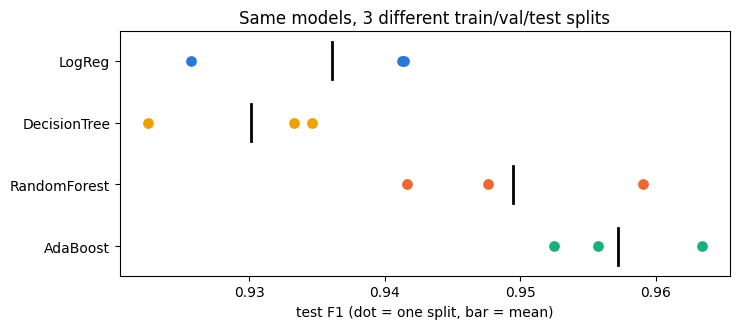

rank of each model per split (1 = best):


model,LogReg,DecisionTree,RandomForest,AdaBoost
seed,,,,
1,3.0,4.0,2.0,1.0
2,3.0,4.0,2.0,1.0
3,3.0,4.0,2.0,1.0


,mean,std,min,max
model,,,,
LogReg,0.9361,0.0090,0.9257,0.9414
DecisionTree,0.9302,0.0067,0.9225,0.9346
RandomForest,0.9494,0.0089,0.9416,0.9591
AdaBoost,0.9572,0.0056,0.9525,0.9634


In [10]:
nn_cfg = json.load(open(MODELS / "neural_net_config.json"))
sk_models = {n: joblib.load(MODELS / f"{n}.joblib") for n in ["LogReg", "DecisionTree", "RandomForest", "AdaBoost"]}
rows = []
for seed in [1, 2, 3]:
    rest_i, te_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(data, groups=data.kepid))
    rest, te = data.iloc[rest_i], data.iloc[te_i]
    tr_i, va_i = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(rest, groups=rest.kepid))
    trn, vln = rest.iloc[tr_i], rest.iloc[va_i]
    Xtr, Xva, Xte = get_X(trn), get_X(vln), get_X(te)
    for n, m in sk_models.items():
        p = clone(m).fit(Xtr, trn.label).predict_proba(Xte)[:, 1]
        rows.append({"seed": seed, "model": n, "test F1": f1_score(te.label, p >= THR[n])})
    if HAS_TORCH:
        prep = make_scaled_pipeline().fit(Xtr)
        predict = train_nn(prep.transform(Xtr), trn.label.values, prep.transform(Xva), vln.label.values, nn_cfg)
        rows.append({"seed": seed, "model": "NeuralNet", "test F1": f1_score(te.label, predict(prep.transform(Xte)) >= THR["NeuralNet"])})
    print(f"seed {seed} done")
rep = pd.DataFrame(rows)
rep.to_csv(RES / "B7_repeated_splits.csv", index=False)

order = [n for n in NAMES if n in set(rep.model)]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for i, n in enumerate(order):
    v = rep[rep.model == n]["test F1"].values
    ax.scatter(v, np.full(len(v), i), color=COLORS[n], s=45, zorder=3)
    ax.plot([v.mean()] * 2, [i - 0.3, i + 0.3], color="black", lw=2)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlabel("test F1 (dot = one split, bar = mean)")
ax.set_title("Same models, 3 different train/val/test splits")
plt.tight_layout(); plt.savefig(FIG / "B7_split_sensitivity.png", dpi=200); plt.show()
print("rank of each model per split (1 = best):")
display(rep.pivot(index="seed", columns="model", values="test F1")[order].rank(axis=1, ascending=False))
rep.groupby("model")["test F1"].agg(["mean", "std", "min", "max"]).loc[order].round(4)

### What to write in the report (Results section)
* The validation comparison and the selection rule → which model is final, and why.
* The one-time test table and confusion matrices; the model ladder figure (best for the poster).
* Level 2 vs Level 1: the test F1 difference, compared with the seed and split variability.
* Threshold table: the precision/recall trade-off.
* Split sensitivity: star vs random folds, and whether the model ranking changes across splits.

**Next:** Hend's failure analysis uses `results/final_choice.json` and the final model's predictions.